In [1]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns
import requests
import zipfile
import io

from sklearn.preprocessing import StandardScaler
from sklearn.cluster import KMeans, AgglomerativeClustering
from sklearn.metrics import silhouette_score
from sklearn.decomposition import PCA
from scipy.cluster.hierarchy import dendrogram, linkage

print("All libraries imported successfully!")

All libraries imported successfully!


In [2]:
url = "https://archive.ics.uci.edu/static/public/292/wholesale+customers.zip"

response = requests.get(url)
response.raise_for_status()

with zipfile.ZipFile(io.BytesIO(response.content)) as z:
    csv_file = next(
        name for name in z.namelist()
        if name.lower().endswith(".csv")
    )
    with z.open(csv_file) as f:
        df = pd.read_csv(f)

print("Dataset downloaded successfully!")
print("Dataset shape:", df.shape)
display(df.head())

Dataset downloaded successfully!
Dataset shape: (440, 8)


,Channel,Region,Fresh,Milk,Grocery,Frozen,Detergents_Paper,Delicassen
0,2,3,12669,9656,7561,214,2674,1338
1,2,3,7057,9810,9568,1762,3293,1776
2,2,3,6353,8808,7684,2405,3516,7844
3,1,3,13265,1196,4221,6404,507,1788
4,2,3,22615,5410,7198,3915,1777,5185


In [3]:
print("Dataset information:")
df.info()

print("\nMissing values:")
print(df.isnull().sum())

print("\nDuplicate records:", df.duplicated().sum())

print("\nStatistical summary:")
display(df.describe().T)

Dataset information:
<class 'pandas.core.frame.DataFrame'>
RangeIndex: 440 entries, 0 to 439
Data columns (total 8 columns):
 #   Column            Non-Null Count  Dtype
---  ------            --------------  -----
 0   Channel           440 non-null    int64
 1   Region            440 non-null    int64
 2   Fresh             440 non-null    int64
 3   Milk              440 non-null    int64
 4   Grocery           440 non-null    int64
 5   Frozen            440 non-null    int64
 6   Detergents_Paper  440 non-null    int64
 7   Delicassen        440 non-null    int64
dtypes: int64(8)
memory usage: 27.6 KB

Missing values:
Channel             0
Region              0
Fresh               0
Milk                0
Grocery             0
Frozen              0
Detergents_Paper    0
Delicassen          0
dtype: int64

Duplicate records: 0

Statistical summary:


,count,mean,std,min,25%,50%,75%,max
Channel,440.0,1.322727,0.468052,1.0,1.00,1.0,2.00,2.0
Region,440.0,2.543182,0.774272,1.0,2.00,3.0,3.00,3.0
Fresh,440.0,12000.297727,12647.328865,3.0,3127.75,8504.0,16933.75,112151.0
Milk,440.0,5796.265909,7380.377175,55.0,1533.00,3627.0,7190.25,73498.0
Grocery,440.0,7951.277273,9503.162829,3.0,2153.00,4755.5,10655.75,92780.0
Frozen,440.0,3071.931818,4854.673333,25.0,742.25,1526.0,3554.25,60869.0
Detergents_Paper,440.0,2881.493182,4767.854448,3.0,256.75,816.5,3922.00,40827.0
Delicassen,440.0,1524.870455,2820.105937,3.0,408.25,965.5,1820.25,47943.0


In [4]:
# Select numerical spending features
features = [
    "Fresh", "Milk", "Grocery",
    "Frozen", "Detergents_Paper", "Delicassen"
]

X = df[features].copy()

# Check data
print("Features selected:", features)
print("Shape:", X.shape)
print("Missing values:", X.isnull().sum().sum())

# Standardize the data
scaler = StandardScaler()
X_scaled = scaler.fit_transform(X)

print("Standardization completed!")
print("Scaled data shape:", X_scaled.shape)

Features selected: ['Fresh', 'Milk', 'Grocery', 'Frozen', 'Detergents_Paper', 'Delicassen']
Shape: (440, 6)
Missing values: 0
Standardization completed!
Scaled data shape: (440, 6)


C:\Users\t480\anaconda3\Lib\site-packages\sklearn\cluster\_kmeans.py:1419: UserWarning: KMeans is known to have a memory leak on Windows with MKL, when there are less chunks than available threads. You can avoid it by setting the environment variable OMP_NUM_THREADS=2.
  warnings.warn(
C:\Users\t480\anaconda3\Lib\site-packages\sklearn\cluster\_kmeans.py:1419: UserWarning: KMeans is known to have a memory leak on Windows with MKL, when there are less chunks than available threads. You can avoid it by setting the environment variable OMP_NUM_THREADS=2.
  warnings.warn(
C:\Users\t480\anaconda3\Lib\site-packages\sklearn\cluster\_kmeans.py:1419: UserWarning: KMeans is known to have a memory leak on Windows with MKL, when there are less chunks than available threads. You can avoid it by setting the environment variable OMP_NUM_THREADS=2.
  warnings.warn(
C:\Users\t480\anaconda3\Lib\site-packages\sklearn\cluster\_kmeans.py:1419: UserWarning: KMeans is known to have a memory leak on Windows wi

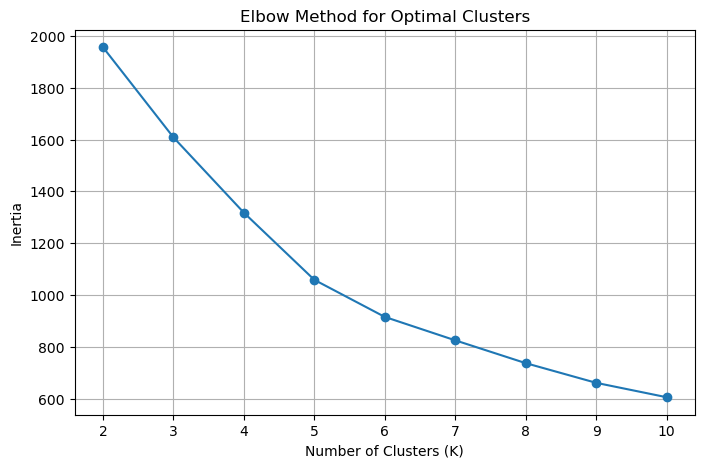

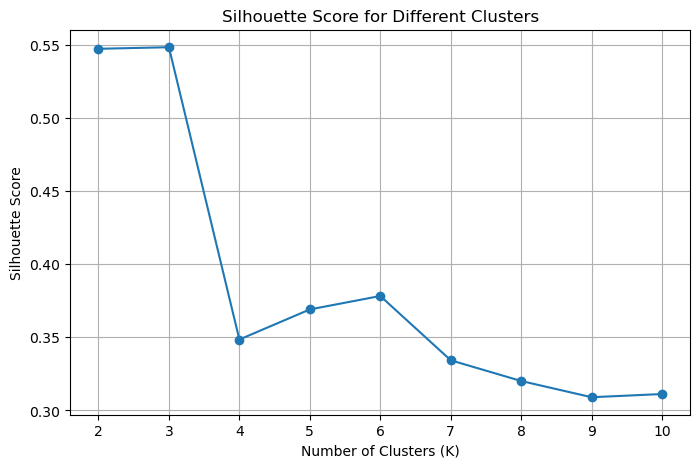

    K      Inertia  Silhouette Score
0   2  1956.124278          0.547215
1   3  1608.431149          0.548287
2   4  1317.838361          0.348471
3   5  1058.771253          0.369040
4   6   915.741260          0.378229
5   7   825.400252          0.334282
6   8   737.386203          0.320116
7   9   661.449585          0.309028
8  10   605.915109          0.311214


In [6]:
inertia = []
silhouette_scores = []
k_values = range(2, 11)

for k in k_values:
    model = KMeans(n_clusters=k, random_state=42, n_init=10)
    labels = model.fit_predict(X_scaled)

    inertia.append(model.inertia_)
    silhouette_scores.append(
        silhouette_score(X_scaled, labels)
    )

# Elbow Method
plt.figure(figsize=(8, 5))
plt.plot(list(k_values), inertia, marker="o")
plt.title("Elbow Method for Optimal Clusters")
plt.xlabel("Number of Clusters (K)")
plt.ylabel("Inertia")
plt.xticks(list(k_values))
plt.grid(True)
plt.savefig("elbow_method.png", bbox_inches="tight")
plt.show()

# Silhouette Score
plt.figure(figsize=(8, 5))
plt.plot(list(k_values), silhouette_scores, marker="o")
plt.title("Silhouette Score for Different Clusters")
plt.xlabel("Number of Clusters (K)")
plt.ylabel("Silhouette Score")
plt.xticks(list(k_values))
plt.grid(True)
plt.savefig("silhouette_scores.png", bbox_inches="tight")
plt.show()

print(pd.DataFrame({
    "K": list(k_values),
    "Inertia": inertia,
    "Silhouette Score": silhouette_scores
}))

In [7]:
kmeans = KMeans(n_clusters=2, random_state=42, n_init=10)

df["KMeans_Cluster"] = kmeans.fit_predict(X_scaled)

print("K-Means clustering completed!")
print(df["KMeans_Cluster"].value_counts().sort_index())

print("\nSilhouette Score:")
print(round(silhouette_score(X_scaled, df["KMeans_Cluster"]), 4))

K-Means clustering completed!
KMeans_Cluster
0    389
1     51
Name: count, dtype: int64

Silhouette Score:
0.5472


C:\Users\t480\anaconda3\Lib\site-packages\sklearn\cluster\_kmeans.py:1419: UserWarning: KMeans is known to have a memory leak on Windows with MKL, when there are less chunks than available threads. You can avoid it by setting the environment variable OMP_NUM_THREADS=2.
  warnings.warn(


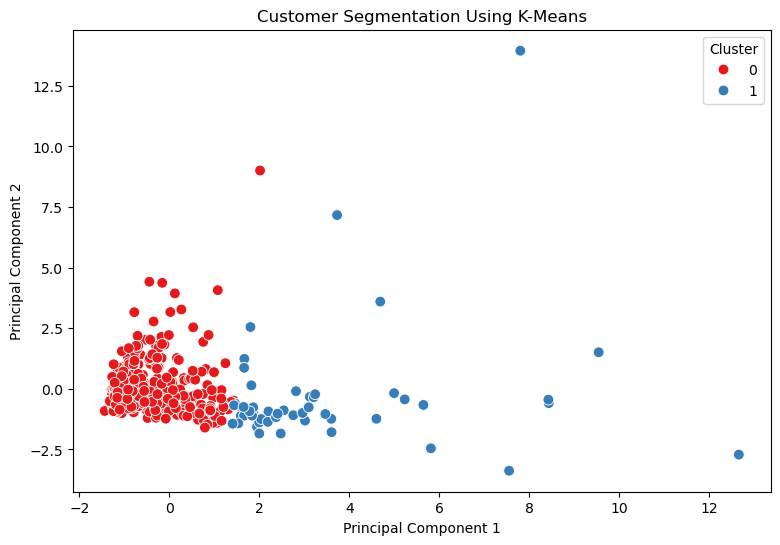

Explained variance: 0.7245929240774498


In [8]:
pca = PCA(n_components=2)
X_pca = pca.fit_transform(X_scaled)

plt.figure(figsize=(9, 6))
sns.scatterplot(
    x=X_pca[:, 0],
    y=X_pca[:, 1],
    hue=df["KMeans_Cluster"],
    palette="Set1",
    s=60
)

plt.title("Customer Segmentation Using K-Means")
plt.xlabel("Principal Component 1")
plt.ylabel("Principal Component 2")
plt.legend(title="Cluster")
plt.savefig("kmeans_customer_clusters.png", bbox_inches="tight")
plt.show()

print("Explained variance:", pca.explained_variance_ratio_.sum())

In [9]:
cluster_profile = df.groupby("KMeans_Cluster")[features].mean().round(2)

print("Customer Cluster Profiles:")
display(cluster_profile)

print("\nCluster sizes:")
display(df["KMeans_Cluster"].value_counts().sort_index())

Customer Cluster Profiles:


,Fresh,Milk,Grocery,Frozen,Detergents_Paper,Delicassen
KMeans_Cluster,,,,,,
0,12157.30,4028.17,5402.72,3066.07,1667.69,1256.89
1,10802.76,19282.33,27390.25,3116.67,12139.73,3568.84



Cluster sizes:


KMeans_Cluster
0    389
1     51
Name: count, dtype: int64

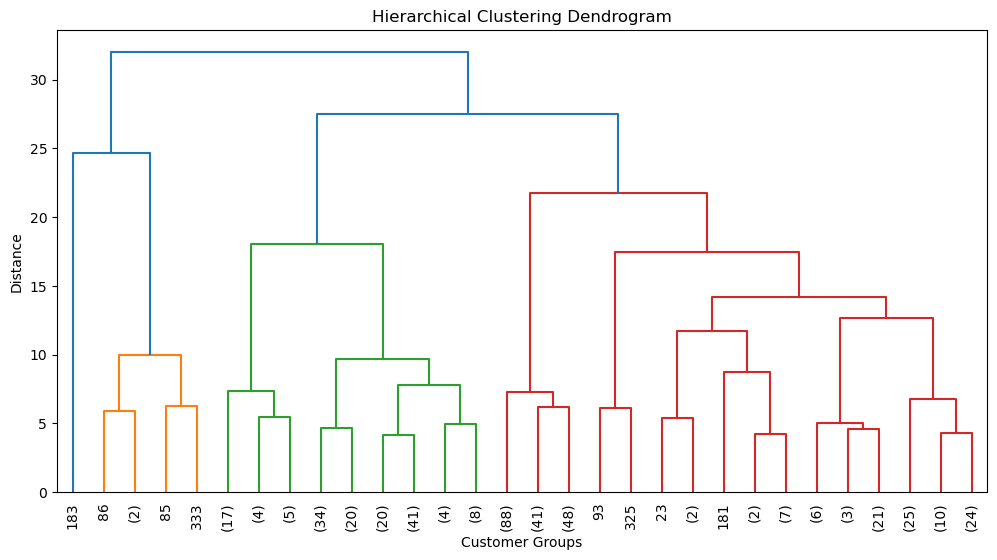

Hierarchical clustering completed!
Hierarchical_Cluster
0    434
1      6
Name: count, dtype: int64
Silhouette Score: 0.7925


In [10]:
# Dendrogram
plt.figure(figsize=(12, 6))
Z = linkage(X_scaled, method="ward")

dendrogram(
    Z,
    truncate_mode="lastp",
    p=30,
    leaf_rotation=90
)

plt.title("Hierarchical Clustering Dendrogram")
plt.xlabel("Customer Groups")
plt.ylabel("Distance")
plt.savefig("hierarchical_dendrogram.png", bbox_inches="tight")
plt.show()

# Apply hierarchical clustering
hierarchical = AgglomerativeClustering(n_clusters=2, linkage="ward")

df["Hierarchical_Cluster"] = hierarchical.fit_predict(X_scaled)

print("Hierarchical clustering completed!")
print(df["Hierarchical_Cluster"].value_counts().sort_index())

print("Silhouette Score:",
      round(silhouette_score(X_scaled, df["Hierarchical_Cluster"]), 4))

In [11]:
kmeans_score = silhouette_score(X_scaled, df["KMeans_Cluster"])
hierarchical_score = silhouette_score(X_scaled, df["Hierarchical_Cluster"])

comparison = pd.DataFrame({
    "Algorithm": ["K-Means", "Hierarchical"],
    "Number of Clusters": [2, 2],
    "Silhouette Score": [kmeans_score, hierarchical_score]
})

display(comparison.round(4))

,Algorithm,Number of Clusters,Silhouette Score
0,K-Means,2,0.5472
1,Hierarchical,2,0.7925


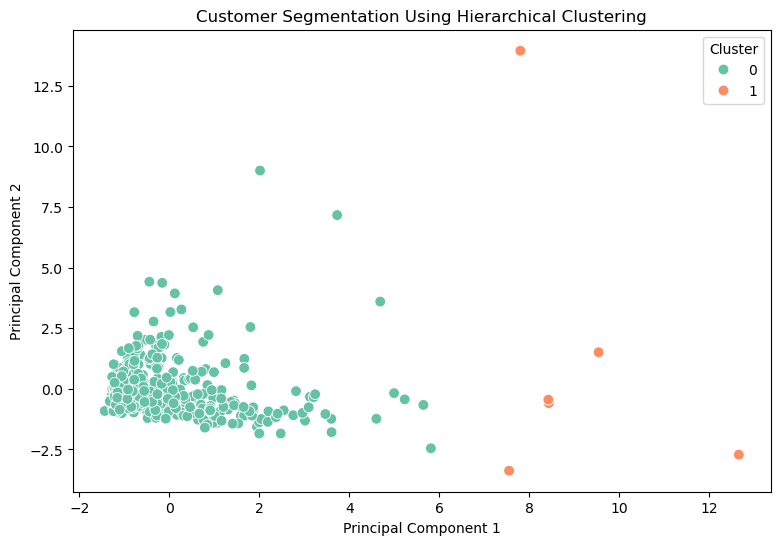

In [12]:
plt.figure(figsize=(9, 6))

sns.scatterplot(
    x=X_pca[:, 0],
    y=X_pca[:, 1],
    hue=df["Hierarchical_Cluster"],
    palette="Set2",
    s=60
)

plt.title("Customer Segmentation Using Hierarchical Clustering")
plt.xlabel("Principal Component 1")
plt.ylabel("Principal Component 2")
plt.legend(title="Cluster")
plt.savefig("hierarchical_customer_clusters.png", bbox_inches="tight")
plt.show()

<Figure size 1200x600 with 0 Axes>

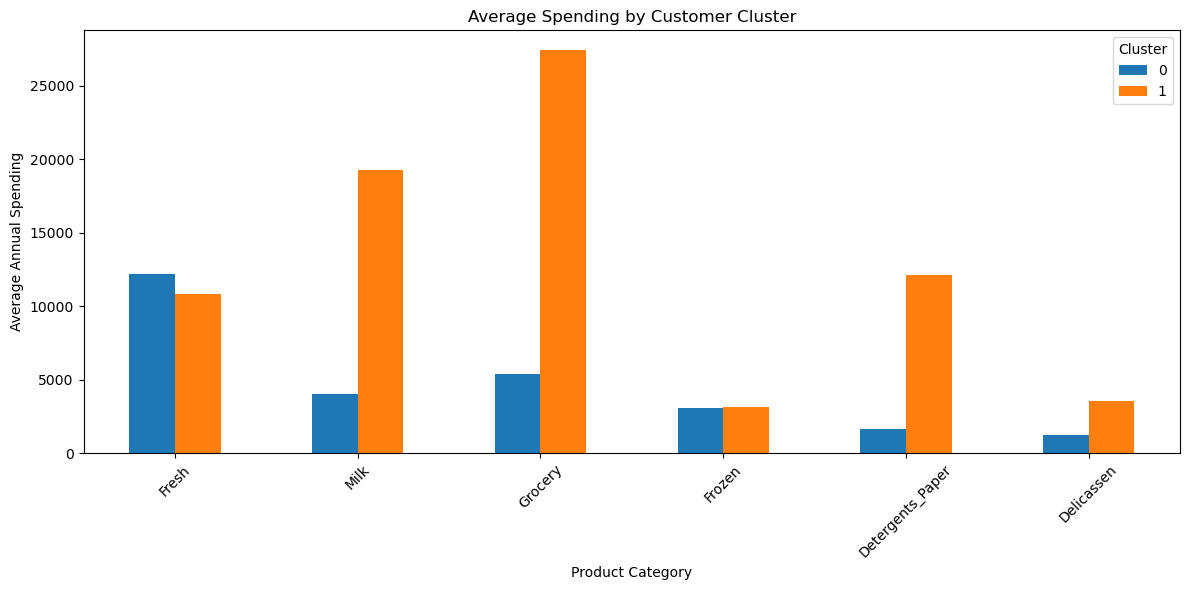

,Fresh,Milk,Grocery,Frozen,Detergents_Paper,Delicassen
KMeans_Cluster,,,,,,
0,12157.30,4028.17,5402.72,3066.07,1667.69,1256.89
1,10802.76,19282.33,27390.25,3116.67,12139.73,3568.84


In [13]:
cluster_comparison = df.groupby("KMeans_Cluster")[features].mean()

plt.figure(figsize=(12, 6))
cluster_comparison.T.plot(kind="bar", figsize=(12, 6))

plt.title("Average Spending by Customer Cluster")
plt.xlabel("Product Category")
plt.ylabel("Average Annual Spending")
plt.xticks(rotation=45)
plt.legend(title="Cluster")
plt.tight_layout()
plt.savefig("cluster_spending_comparison.png", bbox_inches="tight")
plt.show()

display(cluster_comparison.round(2))

In [14]:
df.to_csv("Wholesale_Customer_Clustered_Data.csv", index=False)

cluster_profile.to_csv("Customer_Cluster_Profile.csv")

comparison.to_csv("Clustering_Algorithm_Comparison.csv", index=False)

print("Week 3 analysis files saved successfully!")
print("Final dataset shape:", df.shape)

Week 3 analysis files saved successfully!
Final dataset shape: (440, 10)


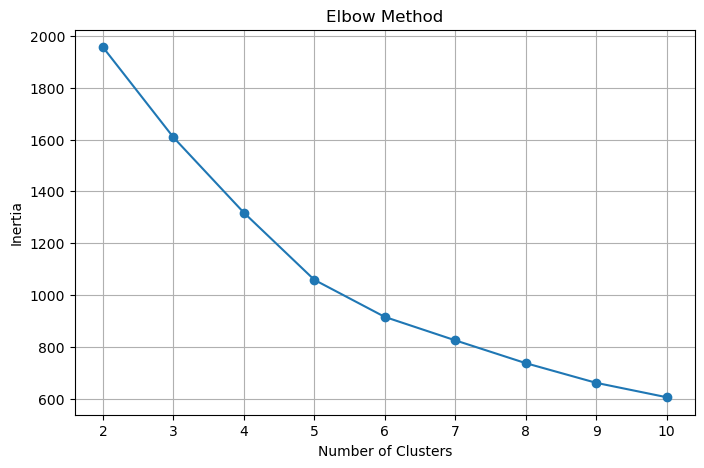

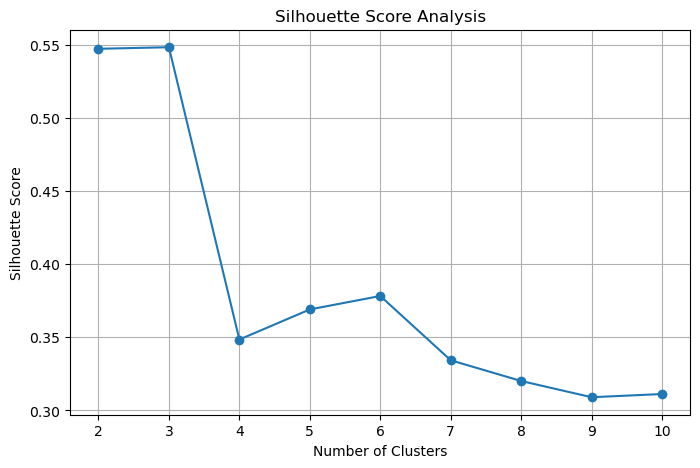

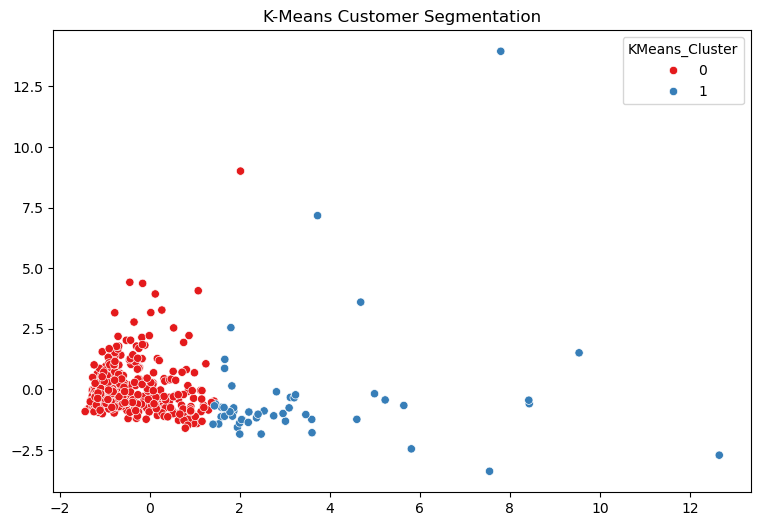

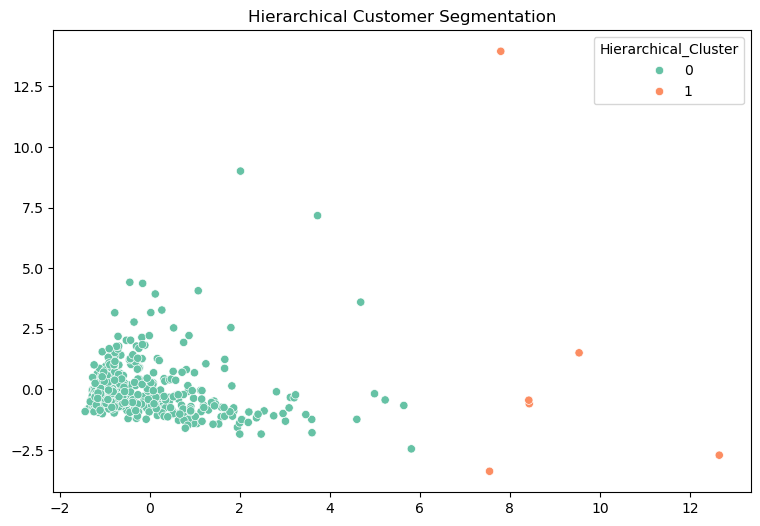

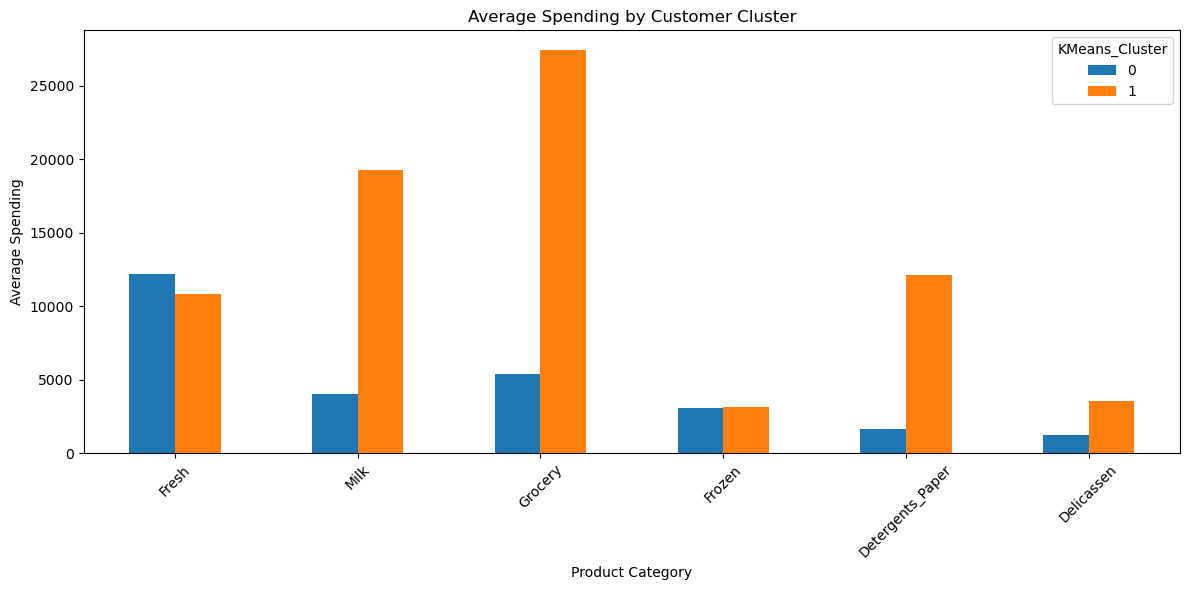

All Week 3 charts saved successfully!


In [15]:
# Save all Week 3 charts

# 1. Elbow Method
plt.figure(figsize=(8, 5))
plt.plot(list(k_values), inertia, marker="o")
plt.title("Elbow Method")
plt.xlabel("Number of Clusters")
plt.ylabel("Inertia")
plt.grid()
plt.savefig("elbow_method.png", dpi=300, bbox_inches="tight")
plt.show()

# 2. Silhouette Scores
plt.figure(figsize=(8, 5))
plt.plot(list(k_values), silhouette_scores, marker="o")
plt.title("Silhouette Score Analysis")
plt.xlabel("Number of Clusters")
plt.ylabel("Silhouette Score")
plt.grid()
plt.savefig("silhouette_scores.png", dpi=300, bbox_inches="tight")
plt.show()

# 3. K-Means Clusters
plt.figure(figsize=(9, 6))
sns.scatterplot(x=X_pca[:, 0], y=X_pca[:, 1],
                hue=df["KMeans_Cluster"], palette="Set1")
plt.title("K-Means Customer Segmentation")
plt.savefig("kmeans_customer_clusters.png", dpi=300, bbox_inches="tight")
plt.show()

# 4. Hierarchical Clusters
plt.figure(figsize=(9, 6))
sns.scatterplot(x=X_pca[:, 0], y=X_pca[:, 1],
                hue=df["Hierarchical_Cluster"], palette="Set2")
plt.title("Hierarchical Customer Segmentation")
plt.savefig("hierarchical_customer_clusters.png", dpi=300, bbox_inches="tight")
plt.show()

# 5. Cluster Spending Comparison
cluster_comparison.T.plot(kind="bar", figsize=(12, 6))
plt.title("Average Spending by Customer Cluster")
plt.xlabel("Product Category")
plt.ylabel("Average Spending")
plt.xticks(rotation=45)
plt.tight_layout()
plt.savefig("cluster_spending_comparison.png", dpi=300, bbox_inches="tight")
plt.show()

print("All Week 3 charts saved successfully!")